In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), _ = keras.datasets.cifar10.load_data()
sample = x_train[5]  # shape (32, 32, 3), dtype uint8, RGB
print(sample.shape, sample.dtype)

I0000 00:00:1794143984.915947 1287032 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794143984.917195 1287032 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794143987.024682 1287032 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794143994.310904 1287032 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

(32, 32, 3) uint8


In [3]:
LUMA = np.array([0.299, 0.587, 0.114]) # Luminanace
def convert2grey(img):
    return np.round(img[..., :3] @ LUMA).astype(np.uint8)

grey = convert2grey(sample)
grey

array([[119, 109, 113, ...,  75,  65,  63],
       [ 94,  93,  98, ..., 108, 112,  73],
       [ 80,  70,  72, ..., 116, 138,  78],
       ...,
       [157, 151, 151, ...,  73,  91, 107],
       [160, 156, 155, ...,  76,  89,  99],
       [164, 160, 159, ...,  79,  84,  90]], shape=(32, 32), dtype=uint8)

In [4]:
sample

array([[[159, 102, 101],
        [150,  91,  95],
        [153,  95,  97],
        ...,
        [ 91,  71,  56],
        [ 74,  63,  55],
        [ 76,  58,  55]],

       [[142,  75,  68],
        [146,  72,  66],
        [155,  76,  65],
        ...,
        [127, 105,  71],
        [122, 111,  93],
        [ 86,  69,  61]],

       [[109,  67,  75],
        [ 99,  58,  60],
        [105,  59,  52],
        ...,
        [137, 112,  80],
        [163, 132, 105],
        [ 93,  72,  71]],

       ...,

       [[244, 129,  70],
        [240, 123,  65],
        [241, 122,  65],
        ...,
        [156,  42,  15],
        [179,  59,  26],
        [200,  73,  36]],

       [[246, 133,  74],
        [243, 128,  72],
        [243, 127,  70],
        ...,
        [162,  44,  14],
        [178,  56,  22],
        [192,  65,  27]],

       [[246, 139,  82],
        [243, 133,  78],
        [244, 132,  77],
        ...,
        [166,  47,  14],
        [173,  51,  17],
        [182,  57,  19]]

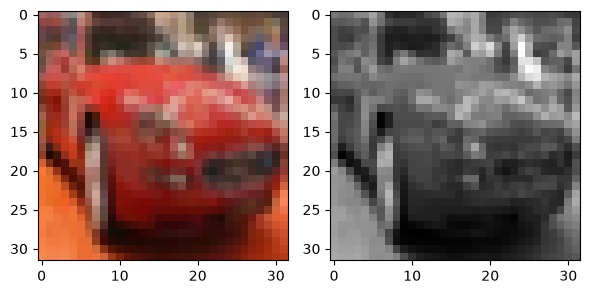

In [5]:

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

ax[0].imshow(sample)
ax[1].imshow(grey, cmap = 'grey')
plt.tight_layout(); plt.show()
plt.show()

In [6]:
def equalize(gray):
    hist = np.bincount(gray.ravel(), minlength=256)
    cdf = hist.cumsum()
    cdf_min = cdf[cdf > 0].min()
    if cdf_min == gray.size:  # constant image, nothing to equalize
        return gray.copy(), np.arange(256, dtype=np.uint8)
    lut = np.round((cdf - cdf_min) / (gray.size - cdf_min) * 255).astype(np.uint8)
    return lut[gray], lut  # lut[gray] = fancy indexing, remaps every pixel

eq, lut = equalize(grey)

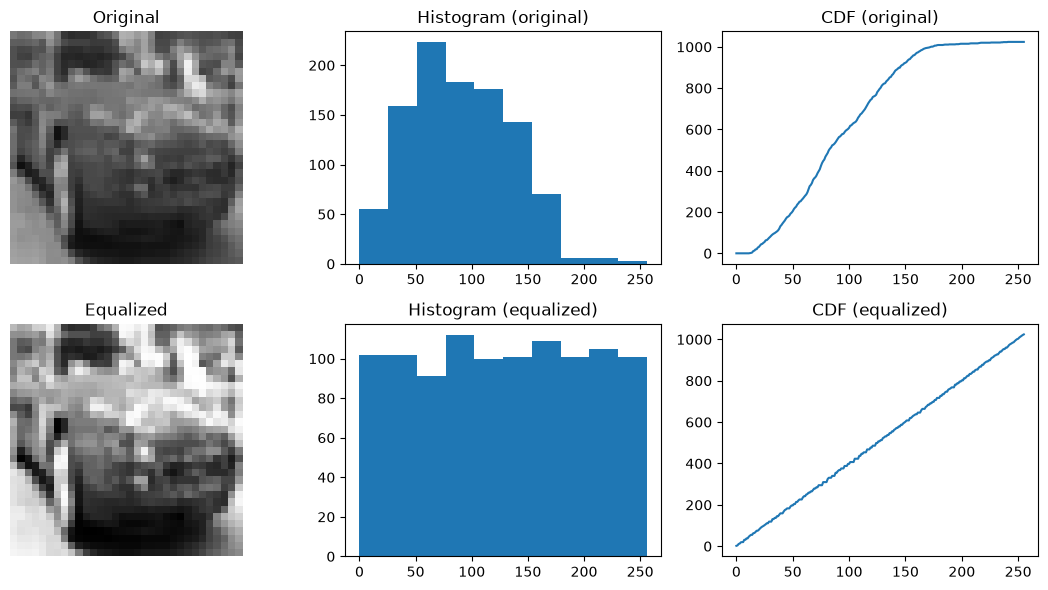

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))

ax[0, 0].imshow(grey, cmap='gray', vmin=0, vmax=255); ax[0, 0].set_title('Original')
ax[0, 1].hist(grey.ravel(), range=(0, 256)); ax[0, 1].set_title('Histogram (original)')
ax[0, 2].plot(np.bincount(grey.ravel(), minlength=256).cumsum()); ax[0, 2].set_title('CDF (original)')

ax[1, 0].imshow(eq, cmap='gray', vmin=0, vmax=255); ax[1, 0].set_title('Equalized')
ax[1, 1].hist(eq.ravel(), range=(0, 256)); ax[1, 1].set_title('Histogram (equalized)')
ax[1, 2].plot(np.bincount(eq.ravel(), minlength=256).cumsum()); ax[1, 2].set_title('CDF (equalized)')

ax[0, 0].axis('off'); ax[1, 0].axis('off')
plt.tight_layout(); plt.show()



In [8]:
eq

array([[185, 165, 172, ..., 105,  81,  73],
       [144, 142, 149, ..., 164, 170,  99],
       [119,  91,  96, ..., 178, 215, 113],
       ...,
       [239, 231, 231, ...,  99, 140, 161],
       [242, 237, 236, ..., 109, 136, 150],
       [245, 242, 241, ..., 116, 128, 138]], shape=(32, 32), dtype=uint8)

In [9]:
G_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

G_y = np.array([
    [-1, 2, -1],
    [0,  0,  0],
    [1,  2,  1]
])




In [10]:
vertically_sharped_grey = np.convolve(sample, G_x)
plt.imshow(vertically_sharped_grey)
plt.show()

ValueError: object too deep for desired array

In [11]:
print("Hello")
np.asarray("Hello")

Hello


array('Hello', dtype='<U5')

In [12]:
print("Hello")

Hello
